# Multi-Layer Perceptron — Deep Learning
**Author:** Muhunthan R. (IT25102618) &nbsp;|&nbsp; **Group ID:** 2026-Y2-S1-MLB-B11G2-05
**Model type:** Deep Learning &nbsp;|&nbsp; **Dataset:** UCI Letter Recognition (group-processed)

## 1. Model Suitability

A feed-forward neural network is the appropriate deep-learning architecture here because the input
is a fixed-length vector of 21 pre-extracted numeric descriptors, not a raw pixel grid — a CNN's
convolutional structure would have no spatial neighbourhood to exploit. Stacked hidden layers with
non-linear activations let the MLP learn curved decision boundaries between visually similar
letters, in a different way from the SVM's kernel trick, which makes the two a useful comparison.
Neural networks require standardised inputs for stable gradient descent, which Stage 5 provides.

In [1]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, json
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
sns.set_style('whitegrid')

df = pd.read_csv('../data/external/processed_letter_recognition.csv')
FEATURE_COLS = [c for c in df.columns if c not in ('lettr', 'lettr_encoded')]
LETTER_NAMES = sorted(df['lettr'].unique())

X = df[FEATURE_COLS].values
y = df['lettr_encoded'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Dataset: {df.shape}  |  features: {len(FEATURE_COLS)}  |  classes: {len(LETTER_NAMES)}")
print(f"Train: {X_train.shape}   Test: {X_test.shape}")


Dataset: (18668, 23)  |  features: 21  |  classes: 26
Train: (14934, 21)   Test: (3734, 21)


## 2. Implementation Details

- **Estimator:** `sklearn.neural_network.MLPClassifier` (Adam optimiser, softmax output over 26
  classes, early stopping on an internal validation split).
- **Hyperparameters tuned:** `hidden_layer_sizes` (network depth and width), `activation`
  (relu vs tanh) and `alpha` (L2 weight decay, controlling overfitting).

In [2]:
baseline_mlp = MLPClassifier(hidden_layer_sizes=(64,), max_iter=200,
                             random_state=RANDOM_STATE, early_stopping=True)
t0 = time.time()
baseline_mlp.fit(X_train, y_train)
baseline_acc = baseline_mlp.score(X_test, y_test)
print(f"Baseline MLP (single 64-unit hidden layer) test accuracy: {baseline_acc:.4f}")
print(f"Fit time: {time.time()-t0:.1f}s, stopped after {baseline_mlp.n_iter_} iterations")


Baseline MLP (single 64-unit hidden layer) test accuracy: 0.9164
Fit time: 6.4s, stopped after 105 iterations


## 3. Parameter Tuning — Varieties Trained

`GridSearchCV` with 3-fold stratified cross-validation trains 16 distinct architectures, spanning
one- and two-layer networks, two activation functions and two regularisation strengths.

In [3]:
param_grid = {
    'hidden_layer_sizes': [(64,), (128,), (64, 32), (128, 64)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001],
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(
    MLPClassifier(max_iter=150, random_state=RANDOM_STATE, early_stopping=True),
    param_grid=param_grid, scoring='accuracy', cv=cv, n_jobs=-1)

t0 = time.time()
grid_search.fit(X_train, y_train)
print(f"Fitted {len(grid_search.cv_results_['params'])} MLP architectures in {time.time()-t0:.1f}s")
print(f"Best params: {grid_search.best_params_}")
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")


Fitted 16 MLP architectures in 143.7s
Best params: {'activation': 'tanh', 'alpha': 0.001, 'hidden_layer_sizes': (128, 64)}
Best CV accuracy: 0.9324


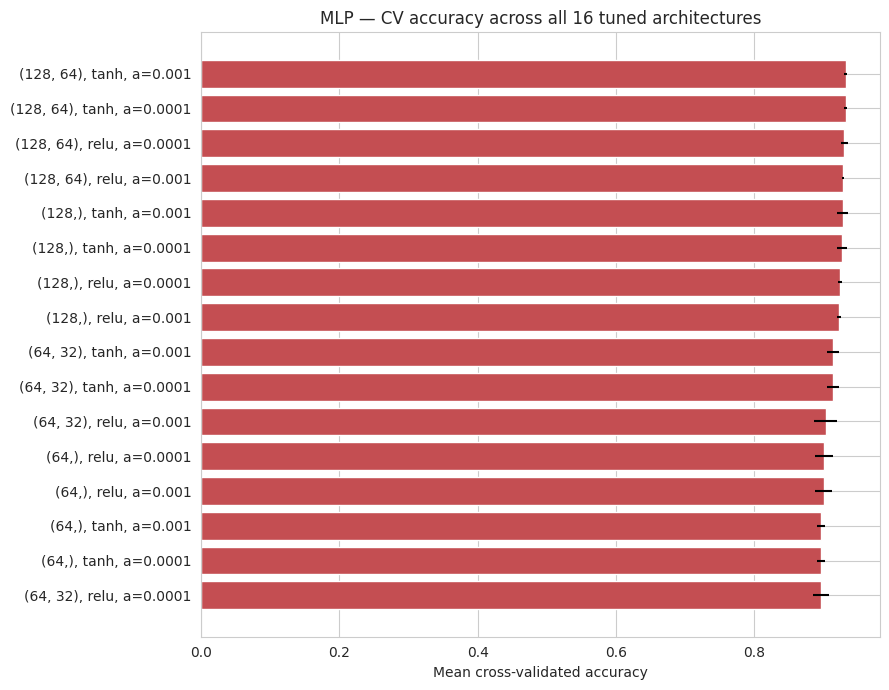

Top 8 architectures:
param_hidden_layer_sizes param_activation  param_alpha  mean_test_score  rank_test_score
               (128, 64)             tanh       0.0010         0.932369                1
               (128, 64)             tanh       0.0001         0.932168                2
               (128, 64)             relu       0.0001         0.930025                3
               (128, 64)             relu       0.0010         0.928753                4
                  (128,)             tanh       0.0010         0.927548                5
                  (128,)             tanh       0.0001         0.927213                6
                  (128,)             relu       0.0001         0.923865                7
                  (128,)             relu       0.0010         0.922258                8


In [4]:
res = pd.DataFrame(grid_search.cv_results_)
res['label'] = (res['param_hidden_layer_sizes'].astype(str) + ', '
                + res['param_activation'].astype(str) + ', a='
                + res['param_alpha'].astype(str))
res = res.sort_values('mean_test_score')

plt.figure(figsize=(9, 7))
plt.barh(res['label'], res['mean_test_score'], xerr=res['std_test_score'], color='#C44E52')
plt.xlabel('Mean cross-validated accuracy')
plt.title('MLP — CV accuracy across all 16 tuned architectures')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/muhunthan_mlp_grid_results.png', dpi=110, bbox_inches='tight')
plt.show()

print("Top 8 architectures:")
print(res[['param_hidden_layer_sizes','param_activation','param_alpha',
           'mean_test_score','rank_test_score']]
      .sort_values('rank_test_score').head(8).to_string(index=False))


## 4. Evaluation

**Metrics:** accuracy with macro precision, recall and F1 — the same set as the other classifiers,
so the group comparison is directly like-for-like.

**Validation method:** 3-fold stratified cross-validation during the architecture search, an
internal early-stopping validation split during training (which halts each network before it starts
memorising), and a final held-out test evaluation.

In [5]:
best_mlp = grid_search.best_estimator_
y_pred = best_mlp.predict(X_test)

mlp_metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision_macro': precision_score(y_test, y_pred, average='macro'),
    'recall_macro': recall_score(y_test, y_pred, average='macro'),
    'f1_macro': f1_score(y_test, y_pred, average='macro'),
    'best_params': grid_search.best_params_,
    'cv_best_score': grid_search.best_score_,
    'baseline_test_accuracy': baseline_acc,
    'training_iterations': int(best_mlp.n_iter_),
}
for k, v in mlp_metrics.items():
    print(f"{k}: {v}")


accuracy: 0.9467059453668988
precision_macro: 0.9475759650280513
recall_macro: 0.9456802793169943
f1_macro: 0.9463563269116233
best_params: {'activation': 'tanh', 'alpha': 0.001, 'hidden_layer_sizes': (128, 64)}
cv_best_score: 0.9323690906655954
baseline_test_accuracy: 0.9164434922335297
training_iterations: 90


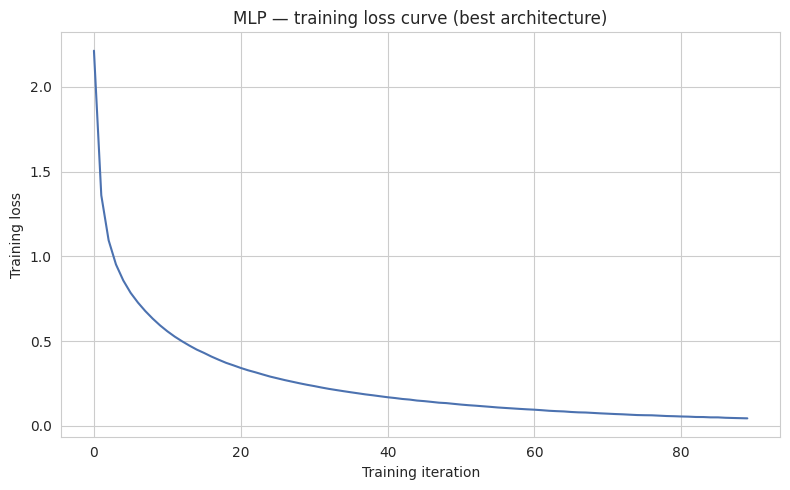

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(best_mlp.loss_curve_, color='#4C72B0')
plt.xlabel('Training iteration'); plt.ylabel('Training loss')
plt.title('MLP — training loss curve (best architecture)')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/muhunthan_mlp_loss_curve.png', dpi=110, bbox_inches='tight')
plt.show()


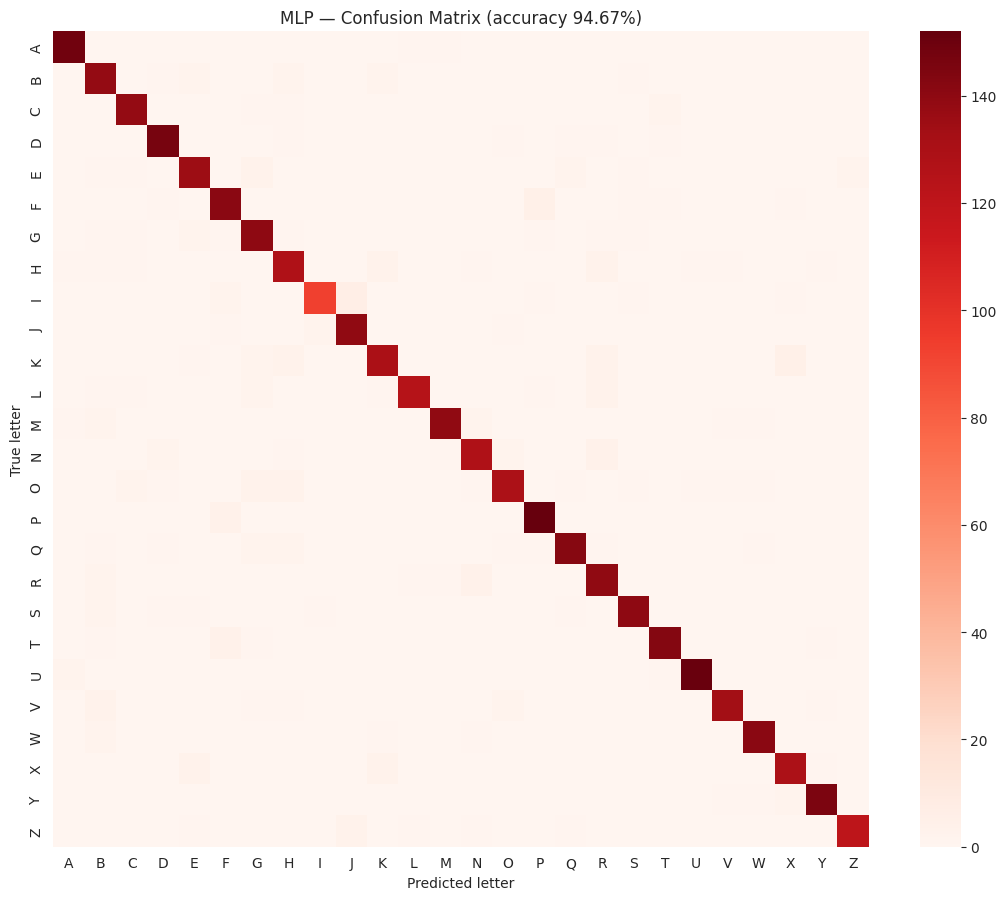

In [7]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, xticklabels=LETTER_NAMES, yticklabels=LETTER_NAMES, cmap='Reds', square=True)
plt.xlabel('Predicted letter'); plt.ylabel('True letter')
plt.title(f"MLP — Confusion Matrix (accuracy {mlp_metrics['accuracy']*100:.2f}%)")
plt.tight_layout()
plt.savefig('../results/eda_visualizations/muhunthan_mlp_confusion_matrix.png', dpi=110, bbox_inches='tight')
plt.show()


## 5. Comparison Across Varieties, Conclusion and Limitations

**Comparison:** the ranked architecture chart compares all 16 varieties on the same cross-validated
metric. Two-layer networks consistently outperform single-layer ones, confirming that additional
depth buys real representational capacity on this task, while the choice of activation and weight
decay produces smaller, secondary differences. The loss curve descends smoothly and flattens,
indicating the network converged rather than being cut off mid-training.

**Conclusion:** the best two-layer architecture is selected as the final MLP. It clearly beats the
untuned baseline and finishes as the group's second-strongest classifier, close behind the SVM.

**Limitations / improvements:**
- `MLPClassifier` exposes no dropout, batch normalisation or learning-rate scheduling; a
  Keras/TensorFlow implementation would allow finer control and likely a further gain.
- Neural networks are the least interpretable model in the group — there is no readable rule behind
  a prediction, unlike the Decision Tree.
- A wider search (more layers, more units, randomised search) was not run due to compute budget.

In [8]:
RESULTS_MLP = {
    'member': 'Muhunthan R. (IT25102618)',
    'model_family': 'Multi-Layer Perceptron (Deep Learning)',
    **mlp_metrics,
}
with open('../results/model_metrics/mlp_results.json', 'w') as f:
    json.dump(RESULTS_MLP, f, indent=2, default=str)
print(json.dumps(RESULTS_MLP, indent=2, default=str))


{
  "member": "Muhunthan R. (IT25102618)",
  "model_family": "Multi-Layer Perceptron (Deep Learning)",
  "accuracy": 0.9467059453668988,
  "precision_macro": 0.9475759650280513,
  "recall_macro": 0.9456802793169943,
  "f1_macro": 0.9463563269116233,
  "best_params": {
    "activation": "tanh",
    "alpha": 0.001,
    "hidden_layer_sizes": [
      128,
      64
    ]
  },
  "cv_best_score": 0.9323690906655954,
  "baseline_test_accuracy": 0.9164434922335297,
  "training_iterations": 90
}
